In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from sklearn.impute import SimpleImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

from analysis_data import load_analysis_frame

analysis_frame = load_analysis_frame("train")
assert isinstance(analysis_frame, pl.DataFrame)

print(f"Jumlah baris: {analysis_frame.height:,}")
print(f"Jumlah kolom: {analysis_frame.width:,}")
print(f"Jumlah shipment unik: {analysis_frame['shipment_id'].n_unique():,}")

Jumlah baris: 1,243,617
Jumlah kolom: 164
Jumlah shipment unik: 1,243,617


In [2]:
excluded_columns = {
    "shipment_id",
    "status_penanganan",
    "customer_id",
    "courier_id",
    "hub_id",
    "package_id",
    "promo_id",
    "event_id",
    "segment_id",
    "invoice_id"
}

numeric_columns = [
    col for col, dtype in analysis_frame.schema.items()
    if dtype.is_numeric()
    and col not in excluded_columns
]

categorical_columns = [
    col for col, dtype in analysis_frame.schema.items()
    if (
        dtype == pl.String
        or dtype == pl.Categorical
        or dtype == pl.Enum
        or dtype == pl.Boolean
    )
    and col not in excluded_columns
    and col != "status_penanganan"
]

print(f"Fitur numerik: {len(numeric_columns)}")
print(f"Fitur kategorikal: {len(categorical_columns)}")

Fitur numerik: 133
Fitur kategorikal: 24


In [3]:
SAMPLE_SIZE = 150_000

# Kolom ID berkardinalitas rendah yang ikut dianalisis di Cramér's V (cell asosiasi kategorikal)
extra_categorical_id_columns = [
    col for col in ["hub_id", "package_id", "promo_id"]
    if col in analysis_frame.columns
]
RANDOM_STATE = 42

sample_size = min(SAMPLE_SIZE, analysis_frame.height)

analysis_sample = (
    analysis_frame
    .sample(n=sample_size, seed=RANDOM_STATE)
    .select(numeric_columns + categorical_columns + extra_categorical_id_columns)
    .to_pandas()
)

print(f"Ukuran sampel: {analysis_sample.shape}")

Ukuran sampel: (150000, 160)


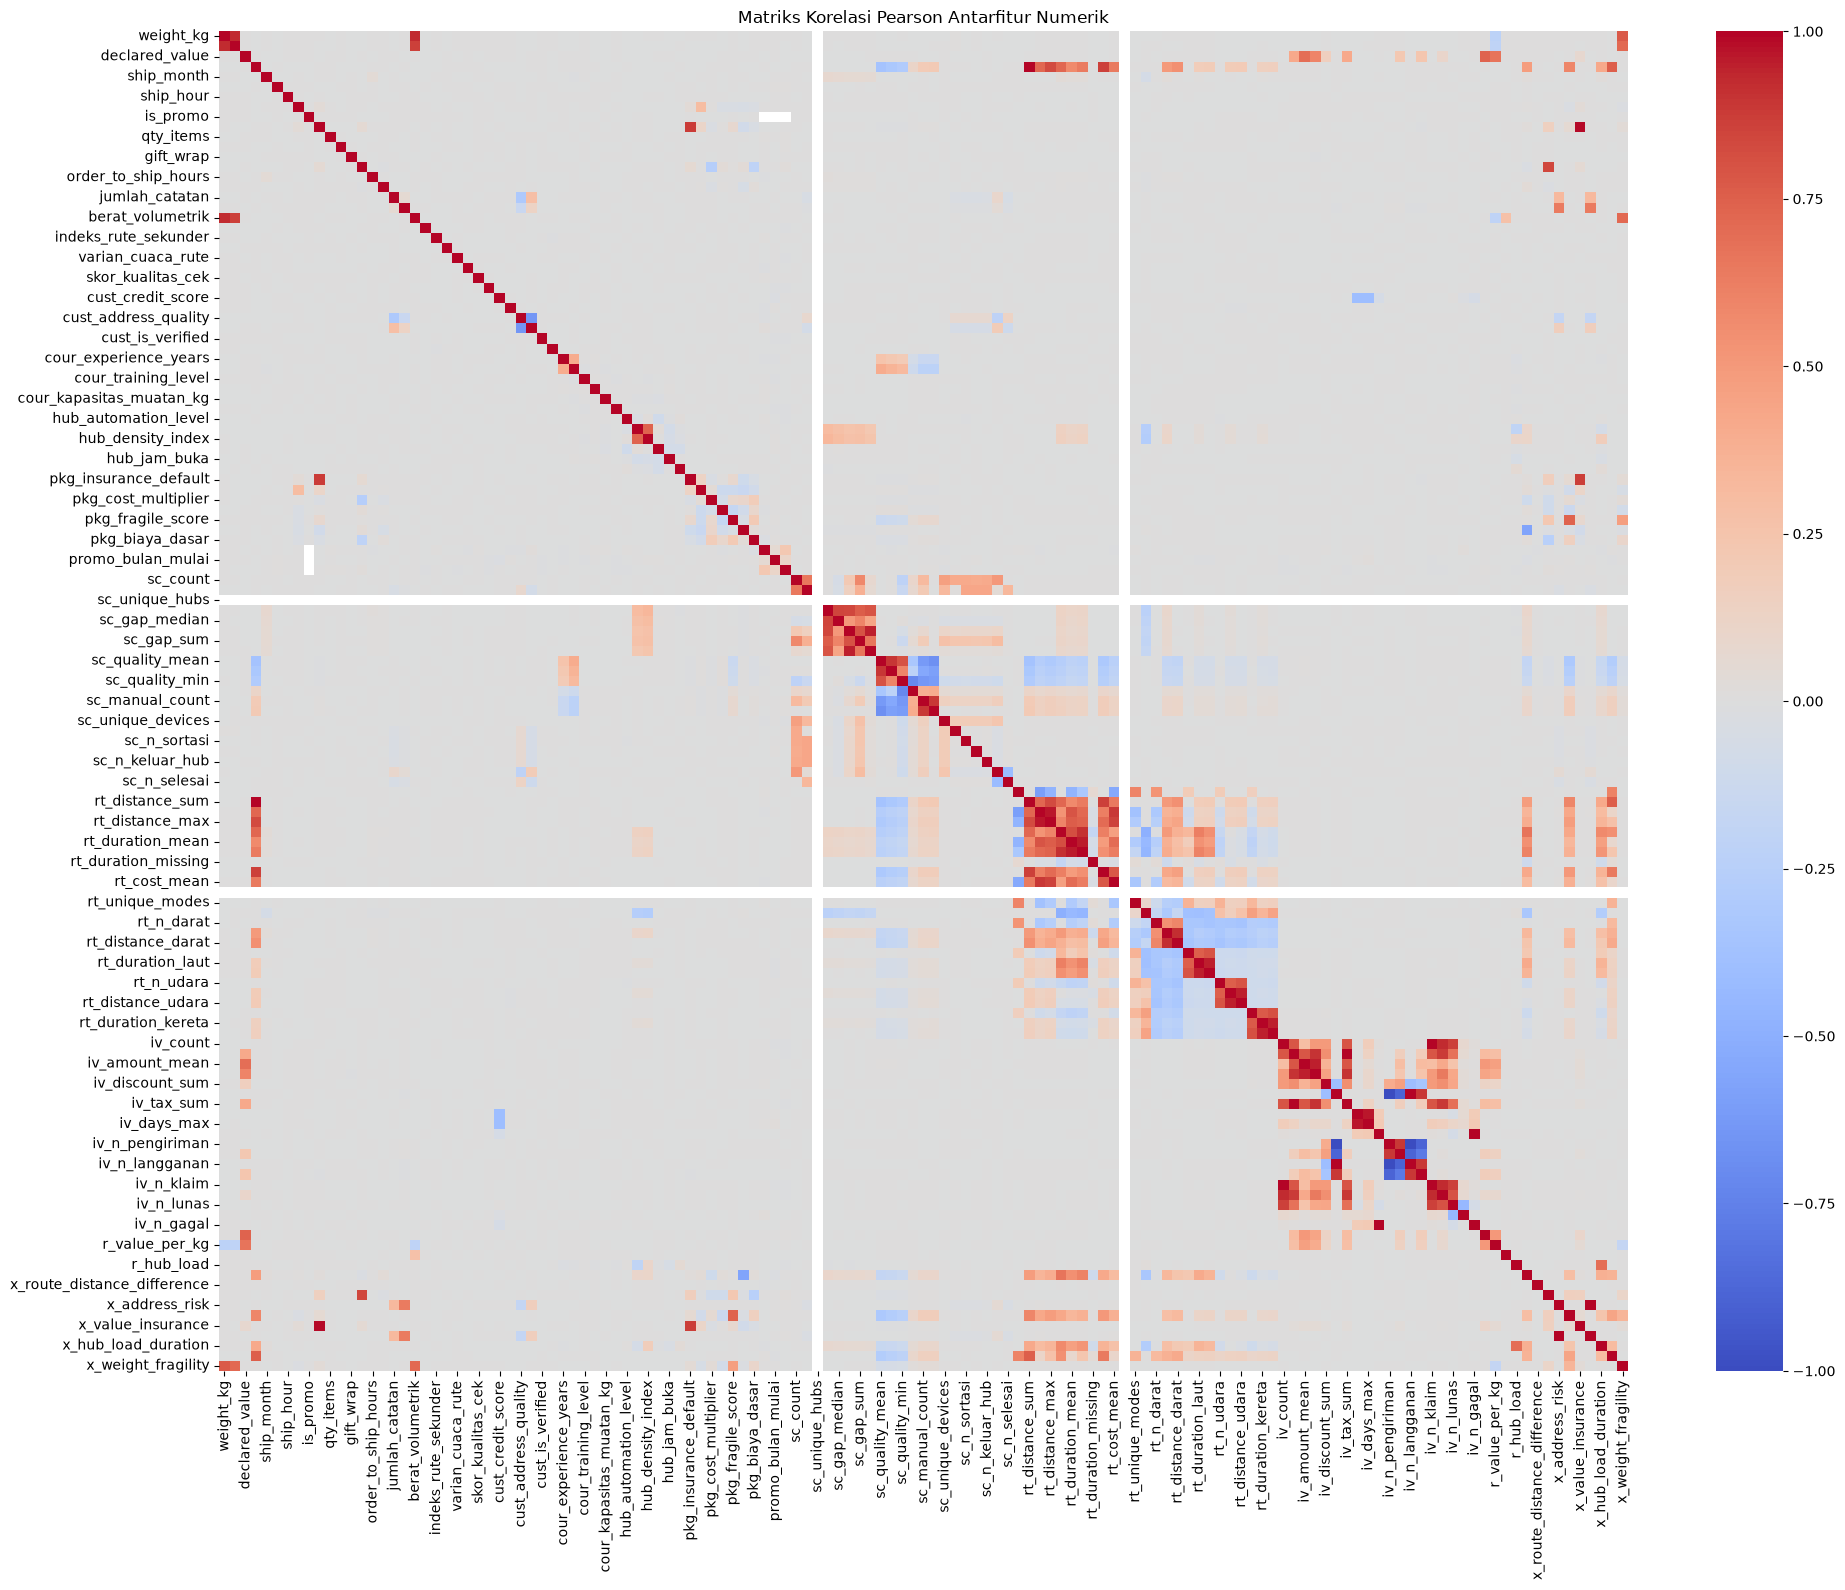

In [4]:
numeric_sample = analysis_sample[numeric_columns].copy()

pearson_corr = numeric_sample.corr(
    method="pearson",
    min_periods=100
)

plt.figure(figsize=(20, 16))
sns.heatmap(
    pearson_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=False
)
plt.title("Matriks Korelasi Pearson Antarfitur Numerik")
plt.tight_layout()
plt.show()

In [5]:
def extract_high_correlations(correlation_matrix, threshold=0.80):
    upper_triangle = correlation_matrix.where(
        np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
    )

    pairs = (
        upper_triangle
        .stack()
        .reset_index()
    )

    pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
    pairs["Absolute Correlation"] = pairs["Correlation"].abs()

    return (
        pairs[pairs["Absolute Correlation"] >= threshold]
        .sort_values("Absolute Correlation", ascending=False)
        .reset_index(drop=True)
    )

pearson_high_corr = extract_high_correlations(
    pearson_corr,
    threshold=0.80
)

display(pearson_high_corr.head(50))
print(f"Jumlah pasangan dengan |Pearson| >= 0.80: {len(pearson_high_corr)}")

,Feature 1,Feature 2,Correlation,Absolute Correlation
0,iv_discount_missing,iv_n_langganan,1.000000,1.000000
1,iv_penalty_count,iv_n_gagal,1.000000,1.000000
2,x_address_risk,x_address_notes,1.000000,1.000000
3,iv_count,iv_n_klaim,1.000000,1.000000
4,iv_n_pengiriman,iv_n_langganan,-1.000000,1.000000
5,iv_discount_missing,iv_n_pengiriman,-1.000000,1.000000
6,distance_km,rt_distance_sum,1.000000,1.000000
7,iv_amount_sum,iv_tax_sum,0.999548,0.999548
8,insurance_opt,x_value_insurance,0.990898,0.990898
9,iv_days_mean,iv_days_max,0.968181,0.968181


Jumlah pasangan dengan |Pearson| >= 0.80: 52


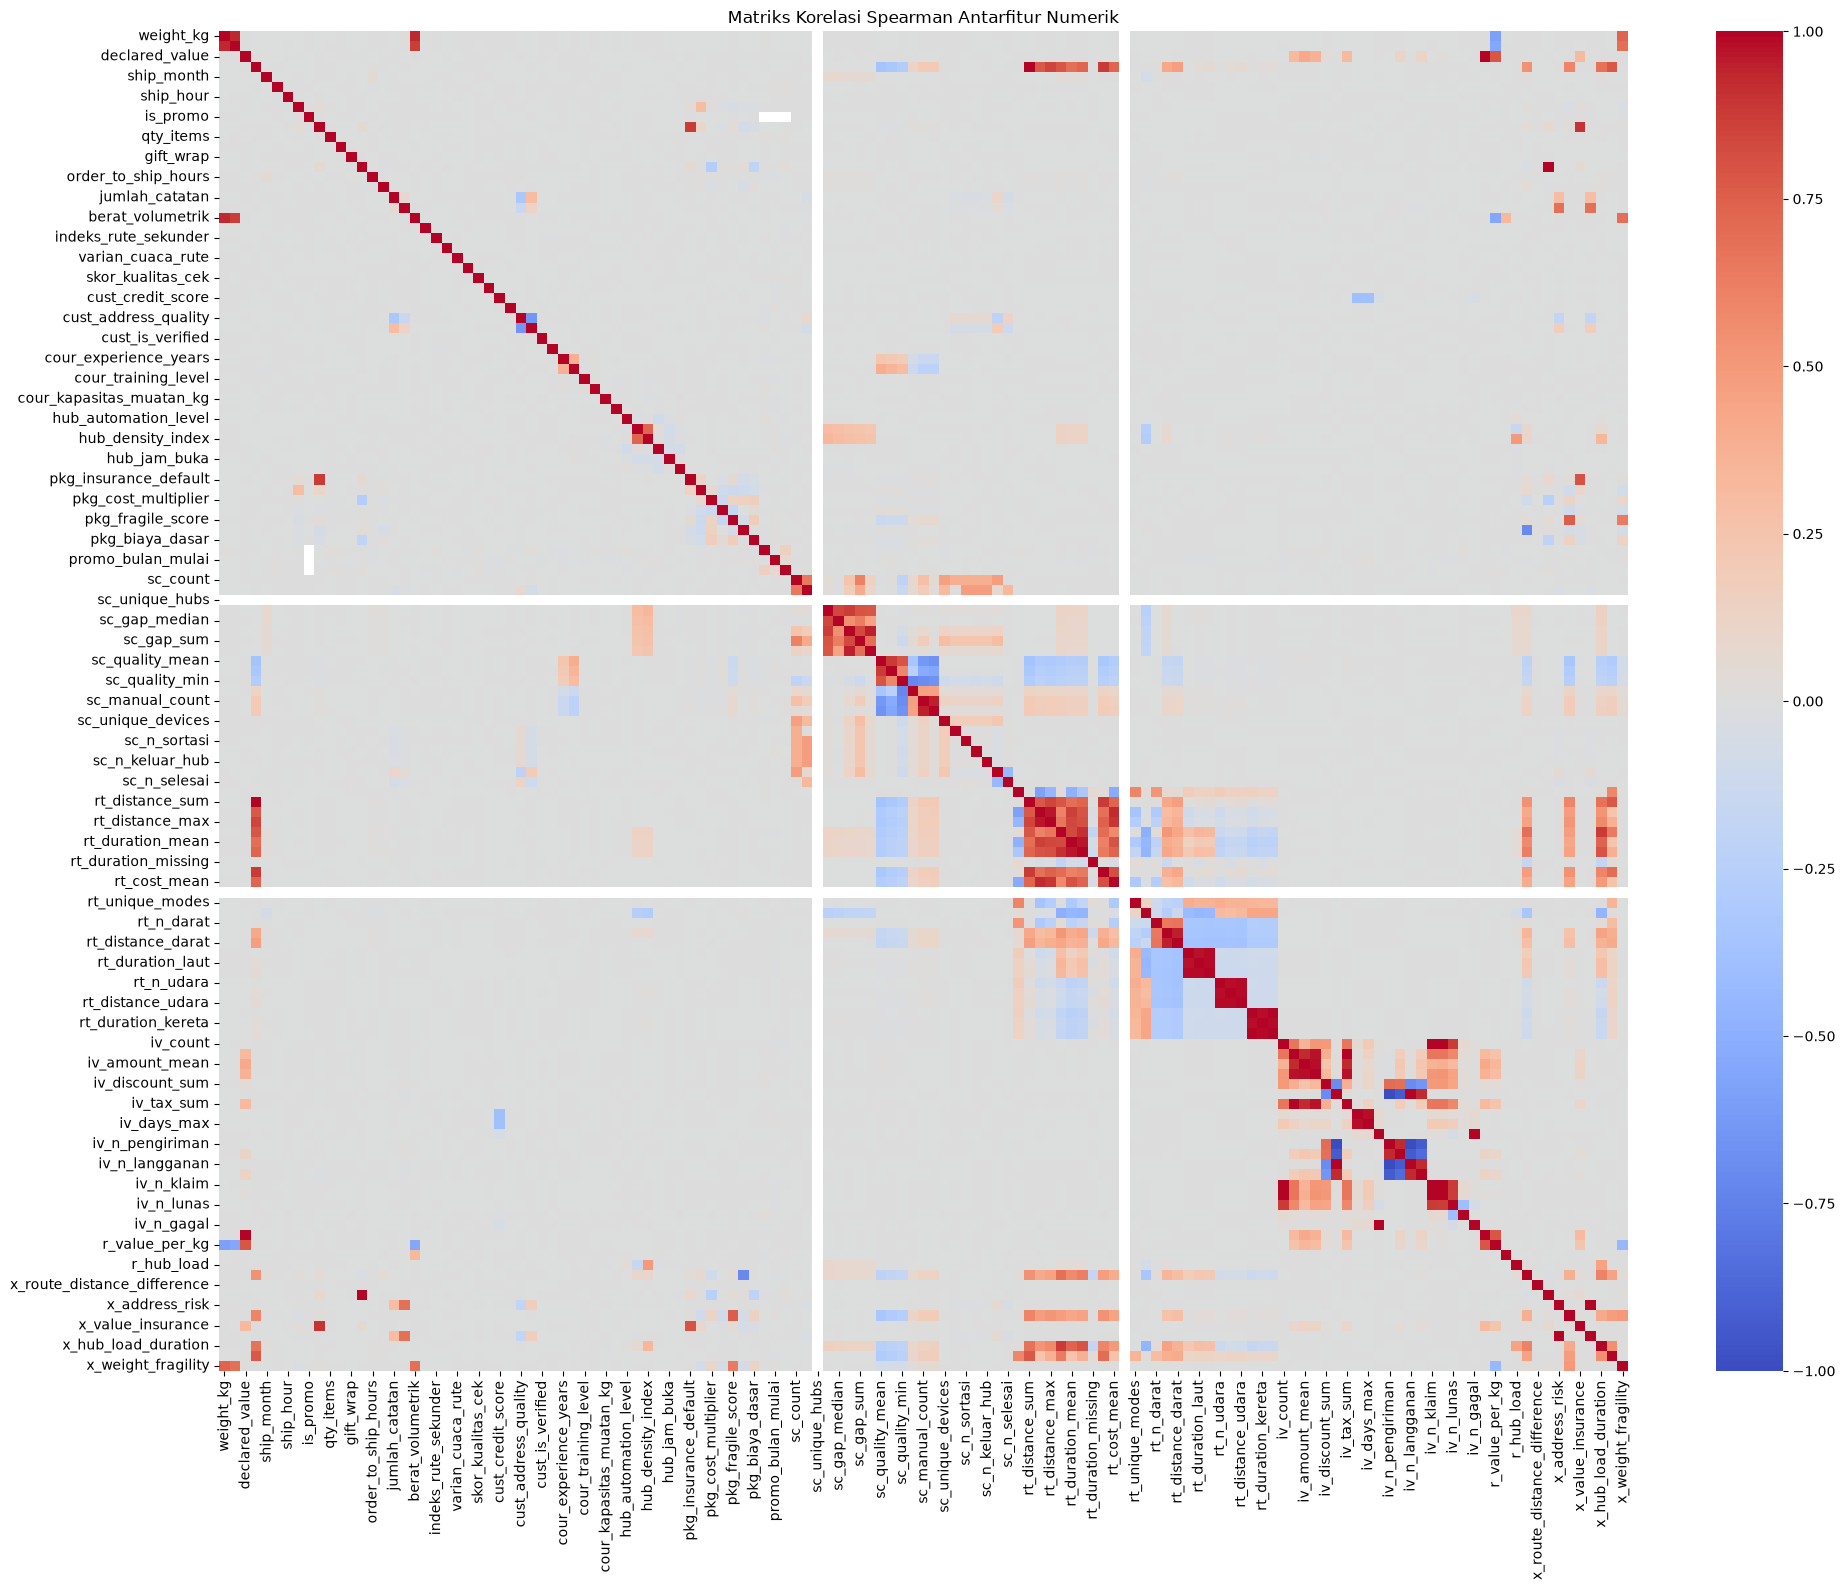

In [6]:
spearman_corr = numeric_sample.corr(
    method="spearman",
    min_periods=100
)

plt.figure(figsize=(20, 16))
sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Matriks Korelasi Spearman Antarfitur Numerik")
plt.tight_layout()
plt.show()

In [7]:
spearman_high_corr = extract_high_correlations(
    spearman_corr,
    threshold=0.80
)

display(spearman_high_corr.head(50))
print(f"Jumlah pasangan dengan |Spearman| >= 0.80: {len(spearman_high_corr)}")

,Feature 1,Feature 2,Correlation,Absolute Correlation
0,iv_discount_missing,iv_n_langganan,1.000000,1.000000
1,declared_value,log_declared_value,1.000000,1.000000
2,x_address_risk,x_address_notes,1.000000,1.000000
3,iv_count,iv_n_klaim,1.000000,1.000000
4,iv_discount_missing,iv_n_pengiriman,-1.000000,1.000000
5,iv_penalty_count,iv_n_gagal,1.000000,1.000000
6,iv_n_pengiriman,iv_n_langganan,-1.000000,1.000000
7,distance_km,rt_distance_sum,1.000000,1.000000
8,iv_amount_sum,iv_tax_sum,0.999980,0.999980
9,fragility_flag,x_fragility,0.996039,0.996039


Jumlah pasangan dengan |Spearman| >= 0.80: 66


In [8]:
pearson_pairs = pearson_high_corr[
    ["Feature 1", "Feature 2", "Correlation"]
].rename(columns={"Correlation": "Pearson"})

spearman_pairs = spearman_high_corr[
    ["Feature 1", "Feature 2", "Correlation"]
].rename(columns={"Correlation": "Spearman"})

correlation_comparison = pearson_pairs.merge(
    spearman_pairs,
    on=["Feature 1", "Feature 2"],
    how="outer"
)

correlation_comparison["Both High"] = (
    correlation_comparison["Pearson"].abs().ge(0.80)
    & correlation_comparison["Spearman"].abs().ge(0.80)
)

correlation_comparison["Pearson-Spearman Difference"] = (
    correlation_comparison["Pearson"]
    - correlation_comparison["Spearman"]
).abs()

correlation_comparison = correlation_comparison.sort_values(
    "Both High",
    ascending=False
)

display(correlation_comparison.head(50))

,Feature 1,Feature 2,Pearson,Spearman,Both High,Pearson-Spearman Difference
67,x_address_risk,x_address_notes,1.000000,1.000000,True,0.000000e+00
39,rt_distance_mean,rt_distance_max,0.965271,0.965174,True,9.664386e-05
29,iv_n_pengiriman,iv_amount_pengiriman,0.886287,0.925676,True,3.938880e-02
30,iv_n_pengiriman,iv_n_langganan,-1.000000,-1.000000,True,3.330669e-16
31,iv_penalty_count,iv_n_gagal,1.000000,1.000000,True,0.000000e+00
61,sc_gap_mean,sc_gap_median,0.848090,0.838885,True,9.205626e-03
33,pkg_insurance_default,x_value_insurance,0.874750,0.800214,True,7.453581e-02
1,distance_km,rt_cost_sum,0.860457,0.878078,True,1.762074e-02
35,rt_distance_max,rt_cost_mean,0.857498,0.893337,True,3.583903e-02
60,sc_gap_mean,sc_gap_max,0.839307,0.867193,True,2.788576e-02


In [9]:
MAX_CATEGORIES = 100

categorical_cardinality = pd.DataFrame({
    "Feature": categorical_columns,
    "Unique Values": [
        analysis_sample[col].nunique(dropna=False)
        for col in categorical_columns
    ]
})

categorical_candidates = (
    categorical_cardinality[
        categorical_cardinality["Unique Values"].between(2, MAX_CATEGORIES)
    ]
    .sort_values("Unique Values")
    .reset_index(drop=True)
)

display(categorical_candidates)

categorical_analysis_features = categorical_candidates[
    "Feature"
].tolist()

print(f"Fitur kategorikal yang dianalisis: {len(categorical_analysis_features)}")

,Feature,Unique Values
0,pickup_type,3
1,cour_shift_code,3
2,cour_contract_type,3
3,cust_kota_tipe,3
4,pkg_speed_class,3
5,pkg_handling_class,3
6,hub_hub_type,3
7,cust_preferred_payment,4
8,cour_vehicle_type,4
9,cust_loyalty_tier,4


Fitur kategorikal yang dianalisis: 23


In [10]:
for col in extra_categorical_id_columns:
    if col in analysis_sample.columns and col not in categorical_analysis_features:
        if analysis_sample[col].nunique(dropna=False) <= MAX_CATEGORIES:
            categorical_analysis_features.append(col)

In [11]:
def calculate_cramers_v(x, y):
    contingency = pd.crosstab(
        x.fillna("__MISSING__").astype(str),
        y.fillna("__MISSING__").astype(str)
    )

    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(contingency, correction=False)[0]
    n = contingency.to_numpy().sum()
    r, k = contingency.shape

    if n <= 1:
        return np.nan

    phi2 = chi2 / n
    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(k_corrected - 1, r_corrected - 1)

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corrected / denominator)

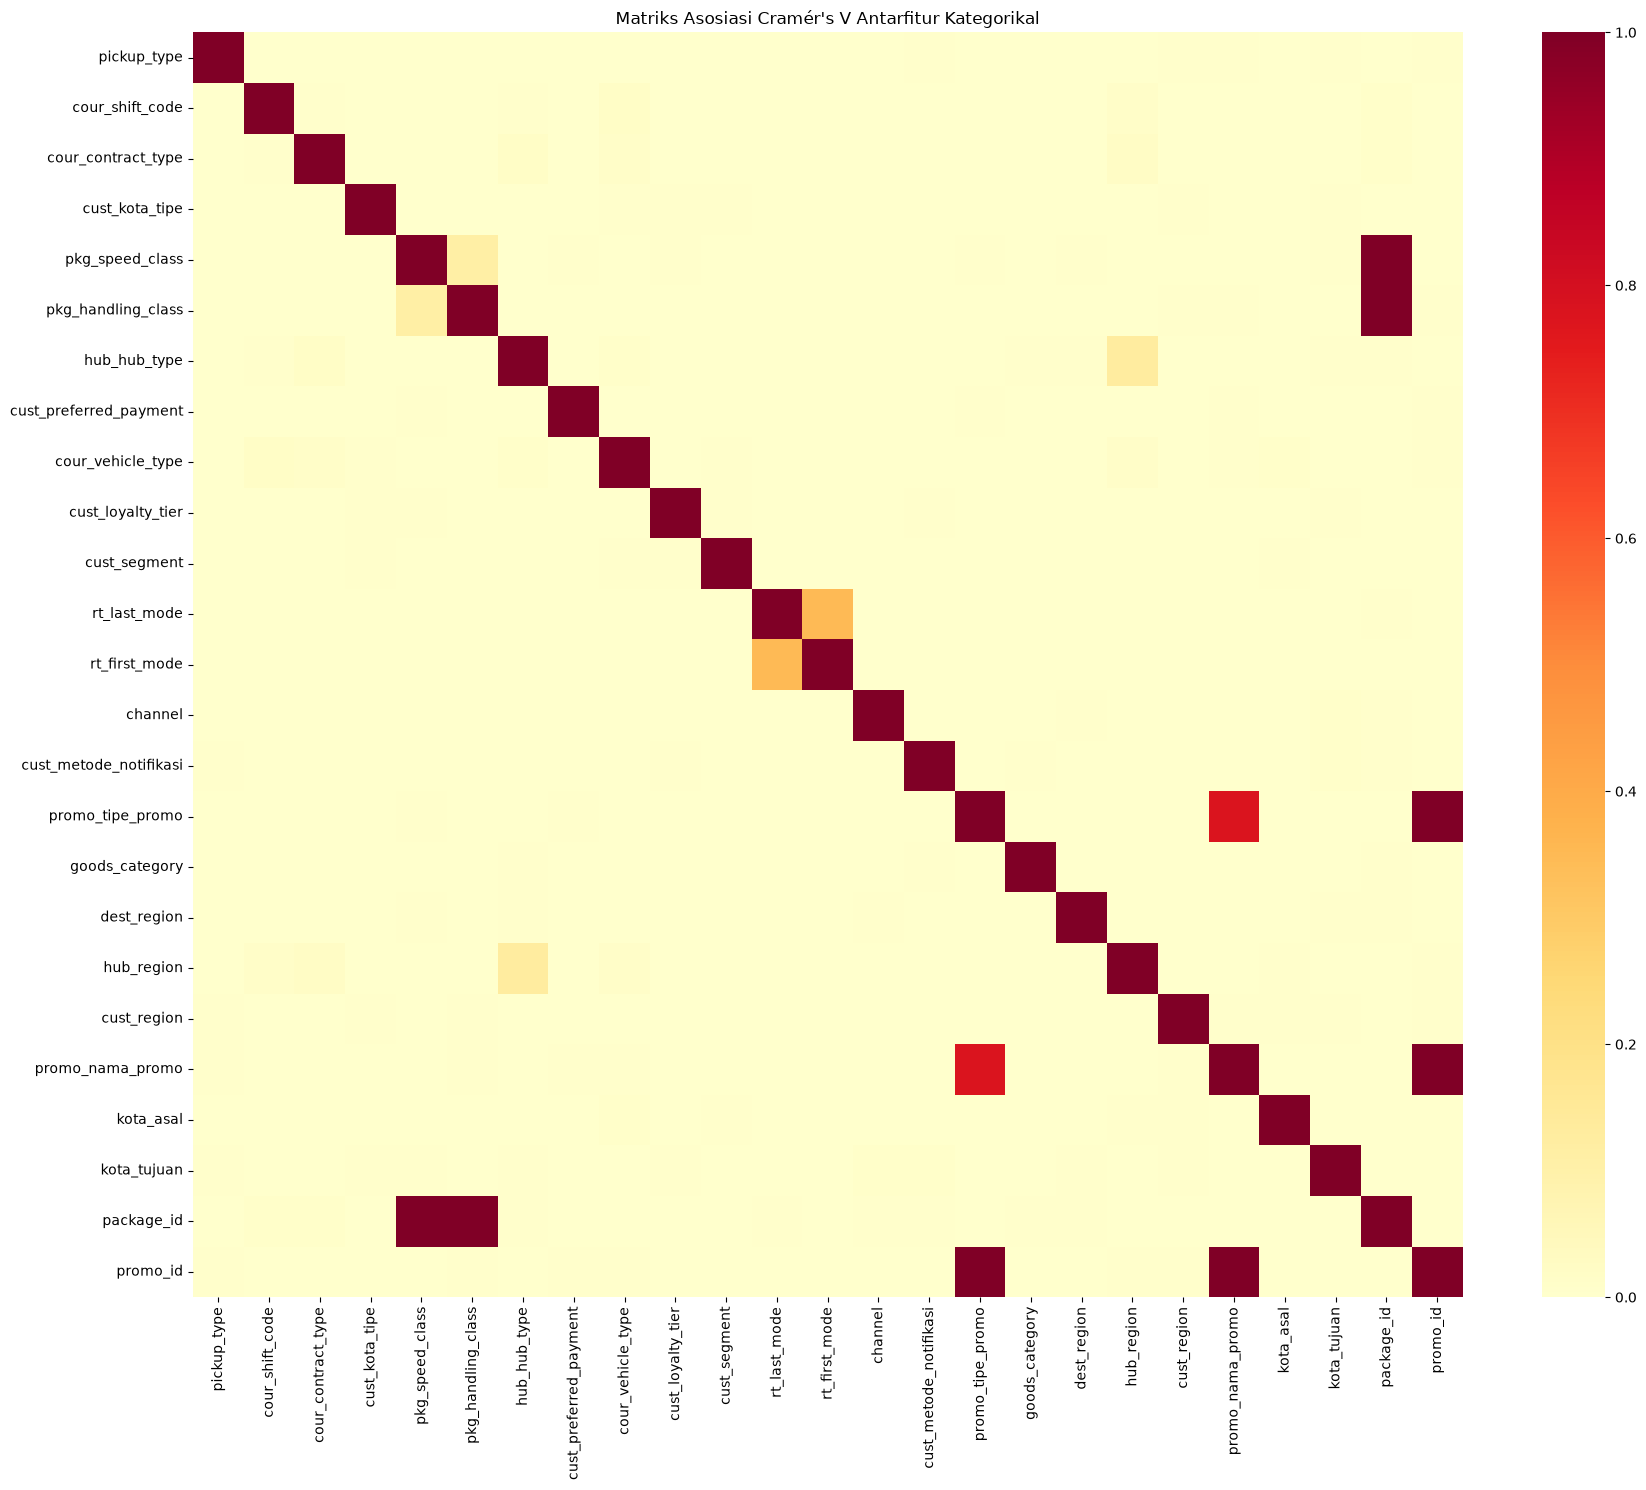

In [12]:
from itertools import combinations

cramers_matrix = pd.DataFrame(
    np.eye(len(categorical_analysis_features)),
    index=categorical_analysis_features,
    columns=categorical_analysis_features
)

for feature_1, feature_2 in combinations(categorical_analysis_features, 2):
    value = calculate_cramers_v(
        analysis_sample[feature_1],
        analysis_sample[feature_2]
    )

    cramers_matrix.loc[feature_1, feature_2] = value
    cramers_matrix.loc[feature_2, feature_1] = value

plt.figure(figsize=(18, 15))
sns.heatmap(
    cramers_matrix,
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)
plt.title("Matriks Asosiasi Cramér's V Antarfitur Kategorikal")
plt.tight_layout()
plt.show()

In [13]:
cramers_pairs = []

for feature_1, feature_2 in combinations(categorical_analysis_features, 2):
    value = cramers_matrix.loc[feature_1, feature_2]

    if pd.notna(value):
        cramers_pairs.append({
            "Feature 1": feature_1,
            "Feature 2": feature_2,
            "Cramers V": value
        })

cramers_high_corr = (
    pd.DataFrame(cramers_pairs)
    .query("`Cramers V` >= 0.50")
    .sort_values("Cramers V", ascending=False)
    .reset_index(drop=True)
)

display(cramers_high_corr)

,Feature 1,Feature 2,Cramers V
0,promo_nama_promo,promo_id,0.999950
1,promo_tipe_promo,promo_id,0.999900
2,pkg_speed_class,package_id,0.999803
3,pkg_handling_class,package_id,0.999803
4,promo_tipe_promo,promo_nama_promo,0.780117


In [14]:
vif_features = [
    col for col in numeric_columns
    if analysis_sample[col].nunique(dropna=True) > 10
]

vif_sample = (
    analysis_sample[vif_features]
    .replace([np.inf, -np.inf], np.nan)
    .copy()
)

vif_sample = vif_sample.dropna(axis=1, how="all")
vif_sample = vif_sample.loc[:, vif_sample.nunique(dropna=True) > 1]

vif_sample = vif_sample.sample(
    n=min(30_000, len(vif_sample)),
    random_state=RANDOM_STATE
)

imputer = SimpleImputer(strategy="median")

vif_values = imputer.fit_transform(vif_sample)

vif_data = pd.DataFrame(
    vif_values,
    columns=vif_sample.columns
)

print(f"Jumlah fitur untuk VIF: {vif_data.shape[1]}")
print(f"Jumlah sampel untuk VIF: {vif_data.shape[0]:,}")

Jumlah fitur untuk VIF: 73
Jumlah sampel untuk VIF: 30,000


In [15]:
import warnings

vif_results = []

vif_array = vif_data.to_numpy(dtype=np.float64)

for i, feature in enumerate(vif_data.columns):
    try:
        # Fitur yang kolinear sempurna memicu SingularMatrixWarning; itu memang yang ingin dideteksi VIF
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            value = variance_inflation_factor(vif_array, i)
    except Exception:
        value = np.inf

    vif_results.append({
        "Feature": feature,
        "VIF": value
    })

vif_results = (
    pd.DataFrame(vif_results)
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(vif_results.head(50))

,Feature,VIF
0,distance_km,1.000800e+15
1,iv_amount_sum,1.000800e+15
2,iv_amount_klaim,1.000800e+15
3,iv_amount_pengiriman,1.000800e+15
4,iv_amount_langganan,1.000800e+15
5,rt_distance_sum,1.000800e+15
6,rt_duration_sum,7.505999e+14
7,rt_distance_darat,6.433714e+14
8,rt_duration_laut,6.433714e+14
9,rt_duration_darat,6.004800e+14


,VIF Category,Jumlah Fitur
0,Rendah,31
1,Sedang,8
2,Tinggi,34


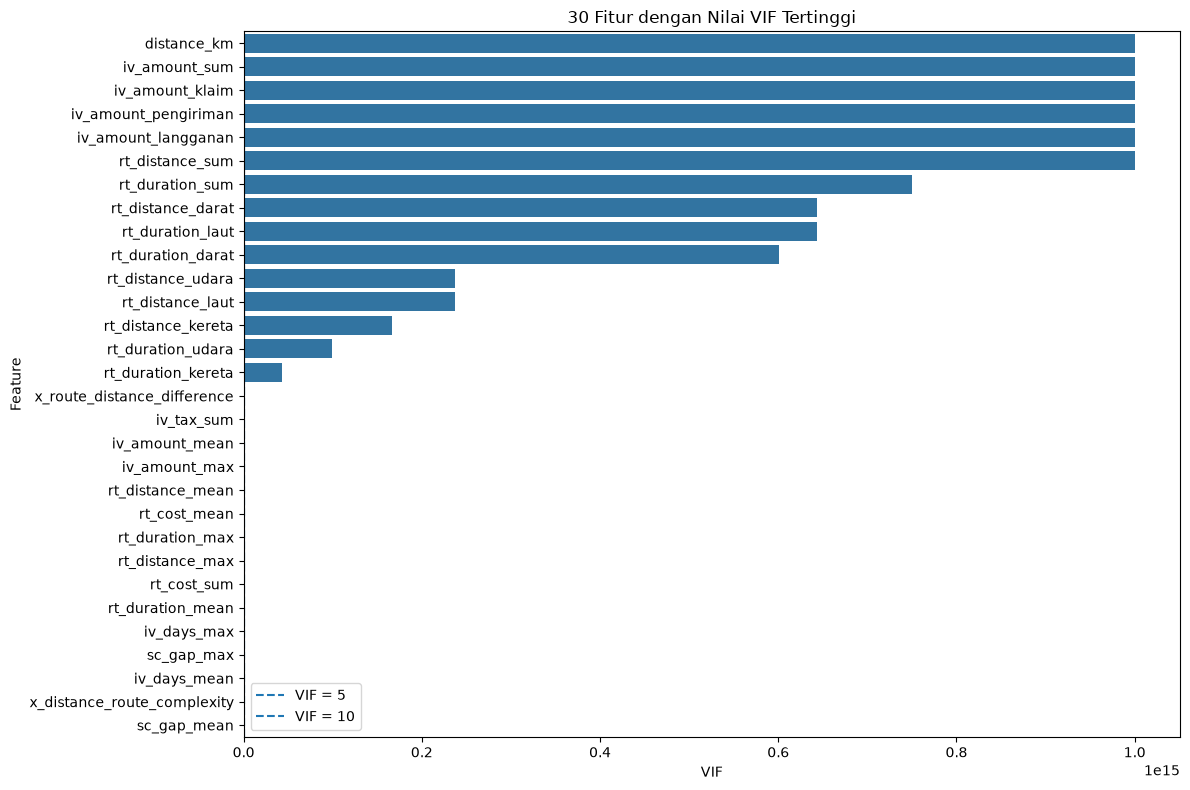

In [16]:
def classify_vif(value):
    if not np.isfinite(value):
        return "Tidak terdefinisi"
    if value > 10:
        return "Tinggi"
    if value > 5:
        return "Sedang"
    return "Rendah"

vif_results["VIF Category"] = vif_results["VIF"].apply(classify_vif)

display(
    vif_results.groupby("VIF Category", dropna=False)
    .size()
    .rename("Jumlah Fitur")
    .reset_index()
)

plt.figure(figsize=(12, 8))

plot_vif = vif_results.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(subset=["VIF"]).head(30)

sns.barplot(
    data=plot_vif,
    x="VIF",
    y="Feature"
)

plt.axvline(5, linestyle="--", label="VIF = 5")
plt.axvline(10, linestyle="--", label="VIF = 10")
plt.title("30 Fitur dengan Nilai VIF Tertinggi")
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
duplicate_numeric_features = []

for feature_1, feature_2 in combinations(numeric_columns, 2):
    series_1 = analysis_sample[feature_1]
    series_2 = analysis_sample[feature_2]

    valid = series_1.notna() & series_2.notna()

    if valid.sum() == 0:
        continue

    identical = (
        series_1[valid].reset_index(drop=True)
        .equals(series_2[valid].reset_index(drop=True))
    )

    if identical:
        duplicate_numeric_features.append({
            "Feature 1": feature_1,
            "Feature 2": feature_2
        })

duplicate_numeric_features = pd.DataFrame(
    duplicate_numeric_features
)

display(duplicate_numeric_features)

,Feature 1,Feature 2
0,sc_unique_hubs,rt_unique_hubs
1,iv_discount_missing,iv_n_langganan
2,x_address_risk,x_address_notes


In [18]:
near_duplicate_features = extract_high_correlations(
    pearson_corr,
    threshold=0.995
)

display(near_duplicate_features)

,Feature 1,Feature 2,Correlation,Absolute Correlation
0,iv_count,iv_n_klaim,1.000000,1.000000
1,x_address_risk,x_address_notes,1.000000,1.000000
2,iv_penalty_count,iv_n_gagal,1.000000,1.000000
3,iv_discount_missing,iv_n_langganan,1.000000,1.000000
4,iv_discount_missing,iv_n_pengiriman,-1.000000,1.000000
5,iv_n_pengiriman,iv_n_langganan,-1.000000,1.000000
6,distance_km,rt_distance_sum,1.000000,1.000000
7,iv_amount_sum,iv_tax_sum,0.999548,0.999548


In [19]:
candidate_feature_pairs = [
    ("distance_km", "rt_distance_sum"),
    ("declared_value", "log_declared_value"),
    ("sc_gap_mean", "sc_gap_median"),
    ("sc_gap_sum", "sc_gap_max"),
    ("sc_quality_mean", "sc_quality_median"),
    ("rt_duration_sum", "rt_duration_mean"),
    ("rt_duration_max", "rt_duration_sum"),
    ("iv_amount_sum", "iv_amount_mean"),
    ("iv_amount_max", "iv_amount_sum")
]

candidate_comparison = []

for feature_1, feature_2 in candidate_feature_pairs:
    if feature_1 not in analysis_sample.columns:
        continue

    if feature_2 not in analysis_sample.columns:
        continue

    pair_data = analysis_sample[[feature_1, feature_2]].dropna()

    if len(pair_data) < 2:
        continue

    candidate_comparison.append({
        "Feature 1": feature_1,
        "Feature 2": feature_2,
        "Pearson": pair_data[feature_1].corr(
            pair_data[feature_2],
            method="pearson"
        ),
        "Spearman": pair_data[feature_1].corr(
            pair_data[feature_2],
            method="spearman"
        ),
        "Exact Match Ratio": (
            pair_data[feature_1].to_numpy()
            == pair_data[feature_2].to_numpy()
        ).mean()
    })

candidate_comparison = pd.DataFrame(candidate_comparison)

display(candidate_comparison)

,Feature 1,Feature 2,Pearson,Spearman,Exact Match Ratio
0,distance_km,rt_distance_sum,1.000000,1.000000,0.970140
1,declared_value,log_declared_value,0.737283,1.000000,0.000000
2,sc_gap_mean,sc_gap_median,0.848090,0.838885,0.030993
3,sc_gap_sum,sc_gap_max,0.800317,0.828188,0.000000
4,sc_quality_mean,sc_quality_median,0.890950,0.879184,0.276820
5,rt_duration_sum,rt_duration_mean,0.813213,0.835415,0.367382
6,rt_duration_max,rt_duration_sum,0.907624,0.909296,0.367402
7,iv_amount_sum,iv_amount_mean,0.788793,0.923562,0.817727
8,iv_amount_max,iv_amount_sum,0.904815,0.971268,0.817727


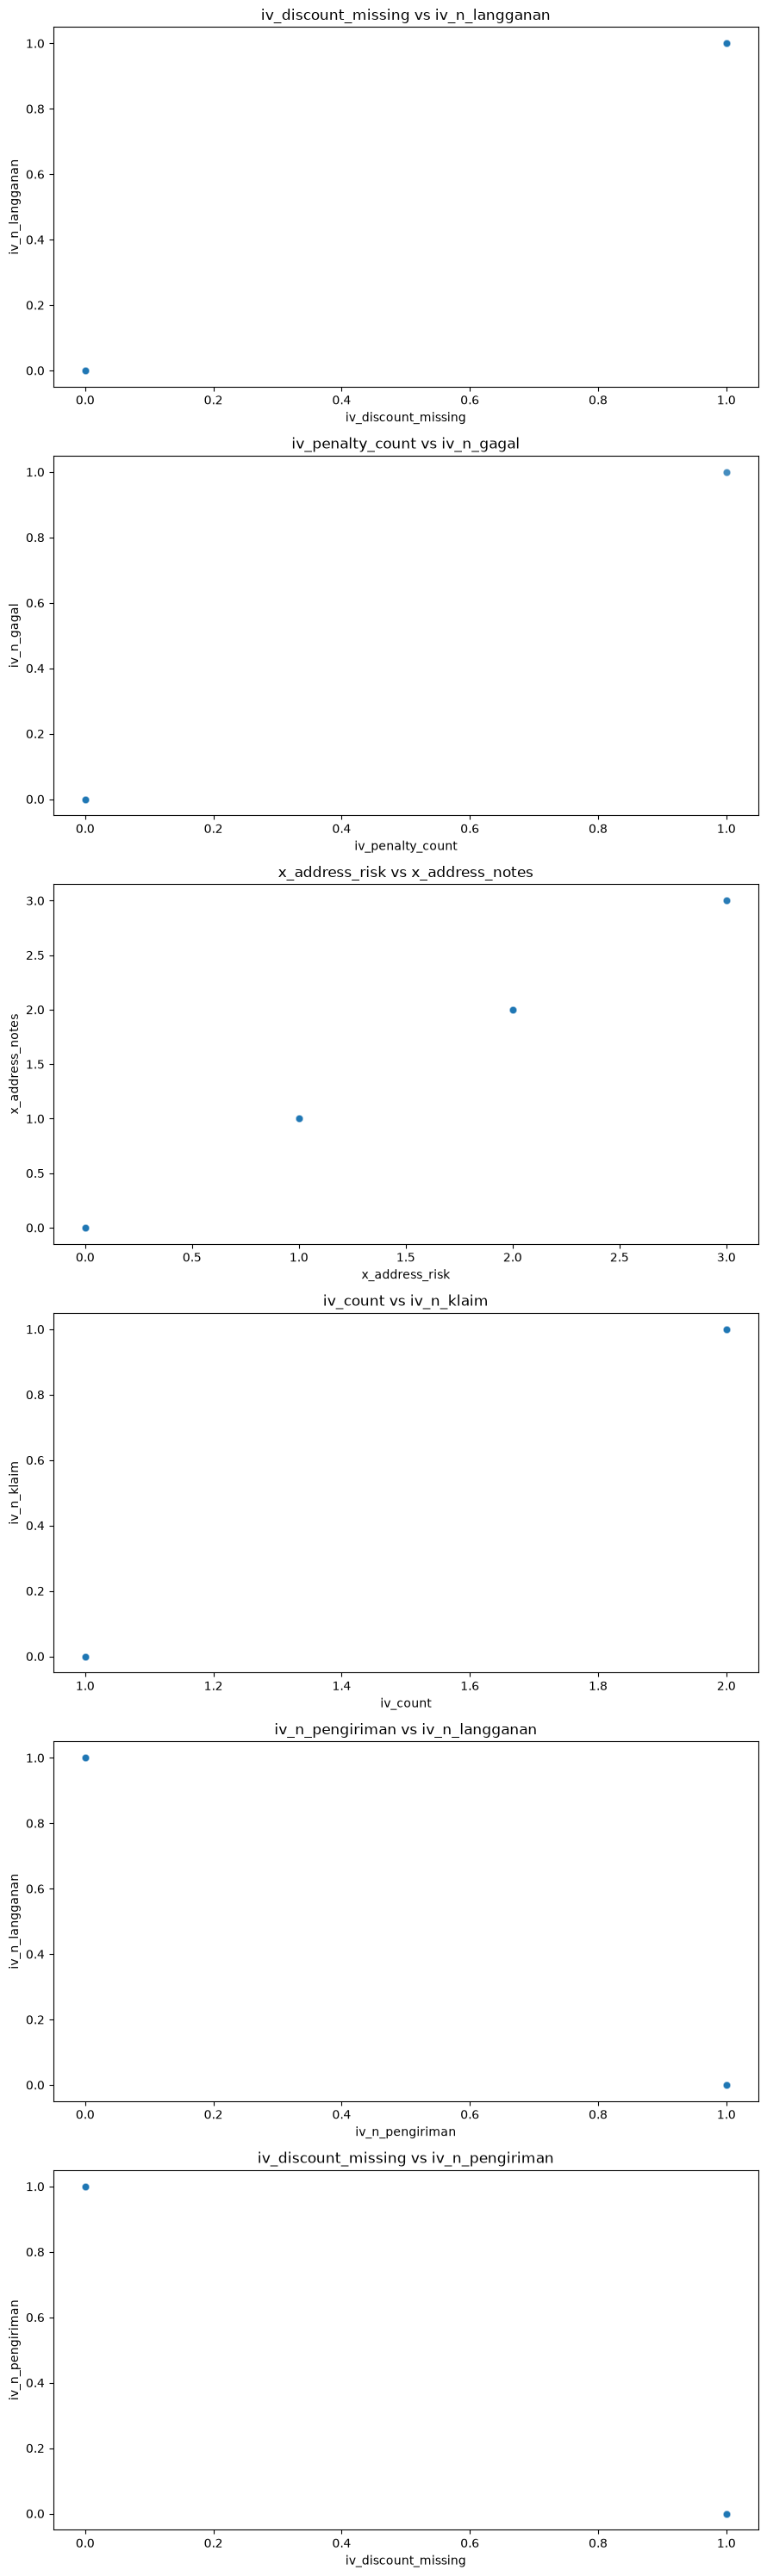

In [20]:
selected_pairs = (
    pearson_high_corr
    .head(6)[["Feature 1", "Feature 2"]]
    .values
    .tolist()
)

fig, axes = plt.subplots(
    nrows=max(1, len(selected_pairs)),
    ncols=1,
    figsize=(9, 5 * max(1, len(selected_pairs)))
)

if len(selected_pairs) == 1:
    axes = [axes]

for ax, (feature_1, feature_2) in zip(axes, selected_pairs):
    sns.scatterplot(
        data=analysis_sample.sample(
            n=min(5000, len(analysis_sample)),
            random_state=RANDOM_STATE
        ),
        x=feature_1,
        y=feature_2,
        alpha=0.25,
        ax=ax
    )

    ax.set_title(f"{feature_1} vs {feature_2}")

plt.tight_layout()
plt.show()

In [21]:
redundancy_candidates = []

for _, row in pearson_high_corr.iterrows():
    redundancy_candidates.append({
        "Feature 1": row["Feature 1"],
        "Feature 2": row["Feature 2"],
        "Method": "Pearson",
        "Association": row["Correlation"],
        "Threshold": 0.80
    })

for _, row in spearman_high_corr.iterrows():
    redundancy_candidates.append({
        "Feature 1": row["Feature 1"],
        "Feature 2": row["Feature 2"],
        "Method": "Spearman",
        "Association": row["Correlation"],
        "Threshold": 0.80
    })

for _, row in cramers_high_corr.iterrows():
    redundancy_candidates.append({
        "Feature 1": row["Feature 1"],
        "Feature 2": row["Feature 2"],
        "Method": "Cramers V",
        "Association": row["Cramers V"],
        "Threshold": 0.50
    })

redundancy_candidates = pd.DataFrame(redundancy_candidates)

if not redundancy_candidates.empty:
    redundancy_candidates = (
        redundancy_candidates
        .sort_values("Association", key=lambda x: x.abs(), ascending=False)
        .reset_index(drop=True)
    )

display(redundancy_candidates)

,Feature 1,Feature 2,Method,Association,Threshold
0,iv_discount_missing,iv_n_langganan,Pearson,1.000000,0.8
1,iv_penalty_count,iv_n_gagal,Pearson,1.000000,0.8
2,x_address_risk,x_address_notes,Pearson,1.000000,0.8
3,iv_count,iv_n_klaim,Pearson,1.000000,0.8
4,iv_count,iv_n_klaim,Spearman,1.000000,0.8
...,...,...,...,...,...
118,rt_n_kereta,rt_distance_kereta,Pearson,0.806375,0.8
119,rt_duration_mean,rt_cost_mean,Spearman,0.803454,0.8
120,sc_gap_max,sc_gap_sum,Pearson,0.800317,0.8
121,pkg_insurance_default,x_value_insurance,Spearman,0.800214,0.8


In [22]:
high_vif_features = (
    vif_results[vif_results["VIF"] > 5]
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

display(high_vif_features)

,Feature,VIF,VIF Category
0,distance_km,1.000800e+15,Tinggi
1,iv_amount_sum,1.000800e+15,Tinggi
2,iv_amount_klaim,1.000800e+15,Tinggi
3,iv_amount_pengiriman,1.000800e+15,Tinggi
4,iv_amount_langganan,1.000800e+15,Tinggi
5,rt_distance_sum,1.000800e+15,Tinggi
6,rt_duration_sum,7.505999e+14,Tinggi
7,rt_distance_darat,6.433714e+14,Tinggi
8,rt_duration_laut,6.433714e+14,Tinggi
9,rt_duration_darat,6.004800e+14,Tinggi


In [23]:
import os

OUTPUT_DIR = "section06_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

pearson_corr.to_csv(
    f"{OUTPUT_DIR}/pearson_correlation_matrix.csv"
)

spearman_corr.to_csv(
    f"{OUTPUT_DIR}/spearman_correlation_matrix.csv"
)

pearson_high_corr.to_csv(
    f"{OUTPUT_DIR}/pearson_high_correlations.csv",
    index=False
)

spearman_high_corr.to_csv(
    f"{OUTPUT_DIR}/spearman_high_correlations.csv",
    index=False
)

cramers_matrix.to_csv(
    f"{OUTPUT_DIR}/cramers_v_matrix.csv"
)

cramers_high_corr.to_csv(
    f"{OUTPUT_DIR}/cramers_high_correlations.csv",
    index=False
)

vif_results.to_csv(
    f"{OUTPUT_DIR}/vif_results.csv",
    index=False
)

duplicate_numeric_features.to_csv(
    f"{OUTPUT_DIR}/duplicate_numeric_features.csv",
    index=False
)

near_duplicate_features.to_csv(
    f"{OUTPUT_DIR}/near_duplicate_features.csv",
    index=False
)

candidate_comparison.to_csv(
    f"{OUTPUT_DIR}/candidate_feature_comparison.csv",
    index=False
)

redundancy_candidates.to_csv(
    f"{OUTPUT_DIR}/redundancy_candidates.csv",
    index=False
)

high_vif_features.to_csv(
    f"{OUTPUT_DIR}/high_vif_features.csv",
    index=False
)

print(f"Seluruh hasil tersimpan di folder: {OUTPUT_DIR}")

Seluruh hasil tersimpan di folder: section06_outputs
